# The collapse law at the teacher fine-tuning stage

Teachers are LoRA fine-tunes of the base models on the animal SFT set — **3–60 total
optimizer steps** (vs students' 1,250–25,000): the few-step, ballistic limit of the same
trajectory physics the student law lives in. This notebook holds the teacher-side results
(2026-08-20/21): the integrity probe over every fine-tuned teacher, the
distillability ⇔ containment equivalence, the law fit on teacher HPs, and the two-term
anatomy/splice tests. Labels and instruments are shared with the student stack: pp1 probe,
declared cut `DEAD_KL_CUT = 4.0`, logistic-50% boundary estimators.

Support: ftseed1 teachers only (the seed that generates pools and is distilled into
students; ftseed0/2 exist but feed nothing). Trees: {dog, cat, lion, pig} ×
{pythia-160m (orig), data-seed1, weight-seed1}. ws1 trees have **no number pools** (never
generated), so they contribute law fits but not yield comparisons — the
`dog-*-teacherft/numgen-top10` queues now training will eventually fill that gap.

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

from subliminal_learning.analysis.setup import bootstrap
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis.probe_cache import load_teacher_probe_cache
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
REPO = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
_, OUT = bootstrap(REPO)[0], bootstrap(REPO)[1]

ANIMALS = ["dog", "cat", "lion", "pig"]
BASES = ["pythia-160m", "pythia-160m-data-seed1", "pythia-160m-weight-seed1"]
BSHORT = {"pythia-160m": "orig", "pythia-160m-data-seed1": "ds1",
          "pythia-160m-weight-seed1": "ws1"}
_hp = re.compile(r"ep(\d+)_lr([0-9.e-]+)_r(\d+)a(\d+)")


def hp_cols(df, tagcol="param_tag"):
    p = df[tagcol].str.extract(_hp)
    return df.assign(ep=p[0].astype(int), lr=p[1].astype(float),
                     rank=p[2].astype(int), alpha=p[3].astype(int))


def load_tree(animal, base, refresh=False):
    t = load_teacher_probe_cache(OUT, Path("teachers") / animal / base, refresh=refresh)
    if len(t) == 0:
        return t
    t = t[t.ftseed == 1].dropna(subset=["kl"])
    return hp_cols(t) if len(t) else t


def pool_table(animal, base):
    rows = []
    for mf in (OUT / "numbers" / animal / base).glob("*/ftseed1/ex10-20/modes/prefix/manifest.json"):
        try:
            m = json.loads(mf.read_text())
        except (json.JSONDecodeError, OSError):
            continue
        rows.append({"param_tag": mf.parts[-6], "n_filtered": m.get("n_filtered"),
                     "keep_rate": m.get("keep_rate")})
    return pd.DataFrame(rows, columns=["param_tag", "n_filtered", "keep_rate"])


TREES = {}
inv = []
for a in ANIMALS:
    for b in BASES:
        t = load_tree(a, b, refresh=True)
        TREES[(a, b)] = t
        pools = pool_table(a, b)
        if len(t) and len(pools):
            t = t.merge(pools, on="param_tag", how="left")
            TREES[(a, b)] = t
        n10 = int((t.n_filtered >= 10000).sum()) if "n_filtered" in t else 0
        finals = len(list((OUT / "teachers" / a / b).glob("*/ftseed1/checkpoints/adapter_model.safetensors")))
        inv.append(dict(animal=a, base=BSHORT[b], finals=finals, probed=len(t),
                        pools=int(t.n_filtered.notna().sum()) if "n_filtered" in t else 0,
                        meets_10k=n10, dead_kl4=int((t.kl > DEAD_KL_CUT).sum()) if len(t) else 0))
display(pd.DataFrame(inv))
print(f"probed = ftseed1 finals with a pp1 probe record at this execution; the "
      f"teacher-pileprobe-xarm queue fills missing trees on re-run. Label: KL > {DEAD_KL_CUT}.")

pile_probe cache: 4791 rows of 29367 cached (4375 added, 0 refreshed, 664 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29367 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29367 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 360 rows of 29367 cached (0 added, 0 refreshed, 720 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29367 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29367 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


... (4 outputs left out)

pile_probe cache: 450 rows of 29367 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29367 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


,animal,base,finals,probed,pools,meets_10k,dead_kl4
0,dog,orig,4735,4735,236,102,1275
1,dog,ds1,450,450,218,118,127
2,dog,ws1,450,450,0,0,129
3,cat,orig,360,360,360,225,132
4,cat,ds1,450,450,360,240,130
5,cat,ws1,450,450,0,0,122
6,lion,orig,288,288,228,96,129
7,lion,ds1,369,369,161,120,123
8,lion,ws1,369,369,0,0,123
9,pig,orig,288,288,225,96,123


probed = ftseed1 finals with a pp1 probe record at this execution; the teacher-pileprobe-xarm queue fills missing trees on re-run. Label: KL > 4.0.


## §1 — teacher integrity distributions

Per-tree probe-KL summary, and the dog|orig histogram (the complete reference tree).
Teachers reach far deeper collapse than students: the student deep-dead mode tops out
~19 nats; hot teacher recipes reach 60–94.

,animal,base,n,kl_med,kl_p75,kl_p95,kl_max,frac_dead
0,dog,orig,4735,0.09,5.9,60.5,112.4,0.27
1,dog,ds1,450,0.11,7.7,44.9,69.0,0.28
2,dog,ws1,450,0.09,7.1,58.6,84.2,0.29
3,cat,orig,360,0.36,18.3,56.8,86.1,0.37
4,cat,ds1,450,0.10,7.6,53.8,67.4,0.29
5,cat,ws1,450,0.08,5.6,57.3,90.2,0.27
6,lion,orig,288,1.82,28.2,69.7,90.6,0.45
7,lion,ds1,369,0.27,14.6,53.5,69.0,0.33
8,lion,ws1,369,0.23,15.3,63.2,95.9,0.33
9,pig,orig,288,1.35,26.8,68.7,95.0,0.43


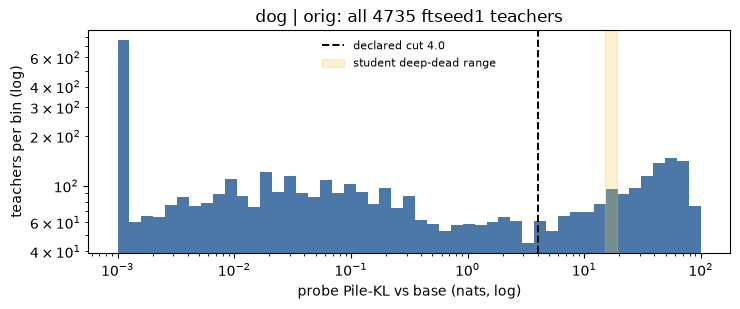

In [2]:
rows = []
for (a, b), t in TREES.items():
    if len(t) == 0:
        continue
    rows.append(dict(animal=a, base=BSHORT[b], n=len(t),
                     kl_med=round(t.kl.median(), 2), kl_p75=round(t.kl.quantile(.75), 1),
                     kl_p95=round(t.kl.quantile(.95), 1), kl_max=round(t.kl.max(), 1),
                     frac_dead=round(float((t.kl > DEAD_KL_CUT).mean()), 2)))
display(pd.DataFrame(rows))

t0 = TREES[("dog", "pythia-160m")]
if len(t0):
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.hist(t0.kl.clip(lower=1e-3), bins=np.logspace(-3, 2, 50), color="#4c78a8")
    ax.axvline(DEAD_KL_CUT, color="k", ls="--", lw=1.4, label=f"declared cut {DEAD_KL_CUT}")
    ax.axvspan(15, 19, color="#f2c94c", alpha=0.25, label="student deep-dead range")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="probe Pile-KL vs base (nats, log)", ylabel="teachers per bin (log)",
           title=f"dog | orig: all {len(t0)} ftseed1 teachers")
    ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

## §2 — distillability ⇔ containment

The ≥10k-usable-sequences criterion ("distillable") against teacher KL, per tree with
pools. On dog|orig the separation is PERFECT (every meets-10k teacher ≤ 2.74 nats, every
failure ≥ 2.94; AUC 1.0). This section tests the replication: per-tree AUC, the
best single KL threshold, and its misclassification count. The scatter shows the shape:
yield is flat at healthy KL, rolls off near the student dead cut, and crashes to ~zero
past it — pool failure is the behavioral face of the teacher's containment failure.

,animal,base,pooled,meets_10k,auc,best_kl_thr,misclassified
0,dog,orig,236,102,1.0000,2.75,0
1,dog,ds1,218,118,0.9988,5.00,4
2,cat,orig,360,225,0.9998,3.00,2
3,cat,ds1,360,240,0.9995,4.75,4
4,lion,orig,228,96,1.0000,3.50,0
5,lion,ds1,161,120,0.9976,6.25,4
6,pig,orig,225,96,0.9999,3.50,2
7,pig,ds1,156,113,0.9994,6.75,2


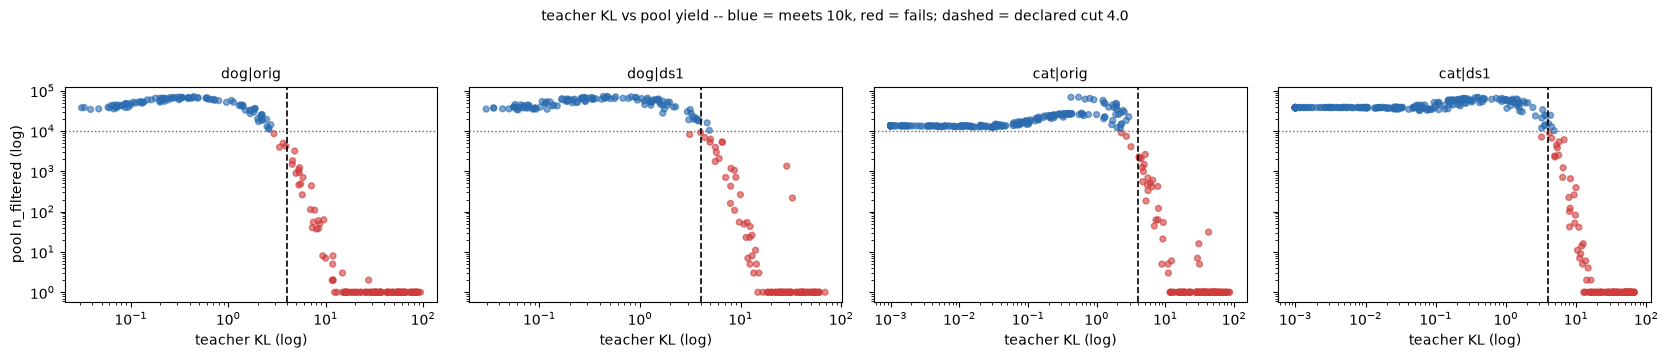

In [3]:
rows, panels = [], []
for (a, b), t in TREES.items():
    if len(t) == 0 or "n_filtered" not in t or t.n_filtered.notna().sum() < 20:
        continue
    g = t.dropna(subset=["n_filtered"]).copy()
    g["ok"] = g.n_filtered >= 10000
    if g.ok.nunique() < 2:
        continue
    auc = roc_auc_score(g.ok, -g.kl)
    best = max(((float(((g.kl <= c) == g.ok).mean()), c) for c in np.arange(0.25, 20, 0.25)))
    rows.append(dict(animal=a, base=BSHORT[b], pooled=len(g), meets_10k=int(g.ok.sum()),
                     auc=round(auc, 4), best_kl_thr=best[1],
                     misclassified=int(round((1 - best[0]) * len(g)))))
    panels.append((f"{a}|{BSHORT[b]}", g))
display(pd.DataFrame(rows))

if panels:
    n = len(panels)
    fig, axs = plt.subplots(1, min(n, 4), figsize=(4.2 * min(n, 4), 3.4), sharey=True,
                            squeeze=False)
    for ax, (name, g) in zip(axs[0], panels[:4]):
        ax.scatter(g.kl.clip(lower=1e-3), g.n_filtered.clip(lower=1), s=18, alpha=0.6,
                   c=np.where(g.ok, "#2b6cb0", "#d03b3b"))
        ax.axvline(DEAD_KL_CUT, color="k", ls="--", lw=1.2)
        ax.axhline(10000, color="#666", ls=":", lw=1)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(name, fontsize=10)
        ax.set_xlabel("teacher KL (log)")
    axs[0][0].set_ylabel("pool n_filtered (log)")
    fig.suptitle("teacher KL vs pool yield -- blue = meets 10k, red = fails; dashed = "
                 f"declared cut {DEAD_KL_CUT}", y=1.04, fontsize=10)
    plt.tight_layout(); plt.show()

## §3 — the law on teacher HPs (cuts 3 and 4)

Teachers add a fourth axis — budget (epochs 1–20 = 3–60 steps) — so the fit is
`dead ~ log lr + log α + log r + log steps` (ridge-stabilised; near-separable). Reported
per tree: the exponent ratios and 4-term AUC at both cuts, then per-epoch logistic-50% K*
at the student display exponents and the K*(T) power law.

**⚠ Exponent caveat (settled 2026-08-21, §3b):** the teacher grid has only 9 near-diagonal
(r, α) combos — rank and alpha are collinear — so the teacher b/c estimates are
DESIGN-CONFOUNDED (refitting the *student* law on this support swings b 0.65 → 1.03 and
flips c). Support-independent teacher results: the KL magnitudes, the distillability
threshold (§2), and K* ∝ T^−0.96 (identified within-tag by budget variation). The
early-vs-late structure question is answered properly by the student trajectory cuts in
§3b, not by this grid.

In [4]:
def law_fit(t, cut):
    y = (t.kl > cut).astype(int)
    steps = t.n_train_steps if "n_train_steps" in t and t.n_train_steps.notna().all() else t.ep * 3
    X = sm.add_constant(pd.DataFrame({
        "log_lr": np.log(t.lr), "log_a": np.log(t.alpha),
        "log_r": np.log(t["rank"]), "log_T": np.log(steps.astype(float))}))
    r = sm.GLM(y, X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    blr = r.params["log_lr"]
    return dict(b=round(r.params["log_a"] / blr, 3), c=round(r.params["log_r"] / blr, 3),
                T_over_lr=round(r.params["log_T"] / blr, 3),
                auc=round(roc_auc_score(y, X @ r.params), 4), n_dead=int(y.sum()))

rows = []
for (a, b), t in TREES.items():
    if len(t) < 100:
        continue
    for cut in (3.0, 4.0):
        if (t.kl > cut).sum() < 20:
            continue
        rows.append(dict(animal=a, base=BSHORT[b], cut=cut, n=len(t), **law_fit(t, cut)))
display(pd.DataFrame(rows))

t0 = TREES[("dog", "pythia-160m")]
if len(t0):
    print("per-epoch logistic-50% K* at display exponents (dog|orig, cut 4):")
    ks = {}
    for ep, g in t0.groupby("ep"):
        y = (g.kl > DEAD_KL_CUT).astype(int)
        if y.sum() < 5 or y.nunique() < 2:
            continue
        try:
            e = cl.kstar_logistic(g.assign(collapsed=y, student_tag=g.param_tag),
                                  cl.B_LAW, cl.C_LAW)
            ks[ep] = e["kstar"]
            print(f"  ep{ep:>2} (~{3*ep} steps): K* {e['kstar']:.3e} "
                  f"(dead {int(y.sum())}/{len(g)})")
        except Exception:
            pass
    if len(ks) >= 3:
        x = np.log([3 * e for e in ks]); yv = np.log(list(ks.values()))
        m = np.polyfit(x, yv, 1)
        print(f"K*(T) power law: K* ∝ steps^{m[0]:.3f} "
              f"(R2 {np.corrcoef(x, yv)[0, 1]**2:.3f}) -- students' budget scaling is far "
              "flatter; this is the ballistic/accumulation limit")

,animal,base,cut,n,b,c,T_over_lr,auc,n_dead
0,dog,orig,3.0,4735,0.777,-0.064,1.219,0.9946,1339
1,dog,orig,4.0,4735,0.781,-0.061,1.205,0.9946,1275
2,dog,ds1,3.0,450,0.890,0.058,1.132,0.9930,138
3,dog,ds1,4.0,450,0.890,0.045,1.118,0.9932,127
4,dog,ws1,3.0,450,0.897,0.071,1.184,0.9940,133
5,dog,ws1,4.0,450,0.910,0.030,1.146,0.9937,129
6,cat,orig,3.0,360,0.827,0.073,1.188,0.9948,133
7,cat,orig,4.0,360,0.829,0.091,1.170,0.9947,132
8,cat,ds1,3.0,450,0.919,0.034,1.128,0.9934,138
9,cat,ds1,4.0,450,0.944,-0.013,1.154,0.9938,130


per-epoch logistic-50% K* at display exponents (dog|orig, cut 4):
  ep 1 (~3 steps): K* 1.047e-02 (dead 17/591)
  ep 2 (~6 steps): K* 4.978e-03 (dead 62/591)
  ep 3 (~9 steps): K* 3.294e-03 (dead 93/591)
  ep 5 (~15 steps): K* 1.814e-03 (dead 142/591)
  ep 7 (~21 steps): K* 1.272e-03 (dead 176/591)
  ep10 (~30 steps): K* 9.548e-04 (dead 217/591)
  ep15 (~45 steps): K* 7.034e-04 (dead 269/591)
  ep20 (~60 steps): K* 5.885e-04 (dead 299/598)
K*(T) power law: K* ∝ steps^-0.980 (R2 0.992) -- students' budget scaling is far flatter; this is the ballistic/accumulation limit


### §3b — regime, not stage: the student law at step 625, and the support diagnostic

Two disk-only tests that separate design artifact from real early-training structure
(Angela 2026-08-21 — no budget-bridge training needed):

1. **Support diagnostic**: the ORIG trees have only 9 near-diagonal (r, α) combos —
   refitting the STUDENT law on that support swings b 0.65 → 1.03 and flips c, so orig-tree
   exponents are unidentifiable. But the ds1/ws1 teacher trees (450 tags, rank 1–64,
   α/r ∈ {1,2,4}) ARE identifiable via the ratio-vs-rank reparametrization
   (dead ~ log lr + log(α/r) + log r + log T), and six independent trees agree:
   **b = 0.82–0.94, c ≈ 0 (−0.04..+0.11), budget/lr ≈ 1.1, AUC 0.994** — the high early
   α exponent AND the absent rank protection are real teacher-stage structure, not design.
   (Residual caveat: α/r spans only 4×; a dozen off-ratio teachers, e.g. r64/α4, would
   sharpen b — the one cheap targeted addition worth considering.)
2. **Trajectory cut**: the student law AT CHECKPOINT 625 (wide identifiable support,
   label = trajectory KL > 4): b ≈ 1.0 early (matching the teacher b — real maturity
   structure) but c ≈ −0.12 (rank protection PRESENT). So rank protection is absent at
   3–60 ballistic steps on ~190 repeated examples and present by 625 student steps —
   an open, well-posed contrast (step regime vs data-repetition regime). And
   K*(625)/K*(25k) ≈ 5.3× over 40× steps → K* ∝ T^−0.45 ≈ √T in the student range vs
   T^−0.96 in the teacher range — the ballistic→diffusive crossover, no new training.

Exposure caveat: a step-625 student has seen ~5k unique examples once; an ep20 teacher has
seen ~190 examples twenty times — the teacher regime is few-DATA (repetition-heavy), not
just few-step, and that difference is not controlled here.

In [5]:
_lad = []
for f in (OUT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m/"
          "ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k").glob("ep20_*/ftseed*/eval/pile_kl_traj.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    pts = {p["step"]: p.get("kl_base_adapted") for p in r.get("points", [])}
    if pts.get(625) is None:
        continue
    last = max(k for k, v in pts.items() if v is not None)
    _lad.append({"tag": f.parts[-4], "kl625": pts[625], "kl_last": pts[last]})
lad = pd.DataFrame(_lad)
qq = lad.tag.str.extract(r"ep20_lr([0-9.e-]+)_r(\d+)a(\d+)")
lad["lr"], lad["rank"], lad["alpha"] = qq[0].astype(float), qq[1].astype(int), qq[2].astype(int)
Xl = sm.add_constant(pd.DataFrame({"llr": np.log(lad.lr), "la": np.log(lad.alpha),
                                   "lr_": np.log(lad["rank"])}))
Kl = lad.lr * lad.alpha**0.561 * lad["rank"]**-0.085

def _fit625(y):
    r_ = sm.GLM(y, Xl, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    r2 = sm.GLM(y, sm.add_constant(np.log(Kl)), family=sm.families.Binomial()).fit()
    return (r_.params["la"] / r_.params["llr"], r_.params["lr_"] / r_.params["llr"],
            float(np.exp(-r2.params.iloc[0] / r2.params.iloc[1])), roc_auc_score(y, Kl))

b6, c6, k6, a6 = _fit625((lad.kl625 > DEAD_KL_CUT).astype(int))
be, ce, ke, ae = _fit625((lad.kl_last > DEAD_KL_CUT).astype(int))
print(f"student law at step 625 (n={len(lad)}): b={b6:.3f}, c={c6:.3f}, K*={k6:.3e}, AUC {a6:.3f}")
print(f"student law at endpoint (25k steps):    b={be:.3f}, c={ce:.3f}, K*={ke:.3e}, AUC {ae:.3f}")
print(f"K*625/K*end = {k6/ke:.2f}x over 40x steps -> K* ∝ T^{np.log(k6/ke)/np.log(1/40):.2f} "
      "(student range) vs T^-0.96 (teacher range, §3)")

student law at step 625 (n=932): b=0.999, c=-0.115, K*=3.747e-03, AUC 0.988
student law at endpoint (25k steps):    b=0.777, c=-0.066, K*=7.122e-04, AUC 0.997
K*625/K*end = 5.26x over 40x steps -> K* ∝ T^-0.45 (student range) vs T^-0.96 (teacher range, §3)


In [6]:
# the identifiable teacher fits: ds1/ws1 trees, ratio-vs-rank reparametrization
rows = []
for a_ in ("dog", "cat", "pig"):
    for b_ in ("pythia-160m-data-seed1", "pythia-160m-weight-seed1"):
        t = TREES.get((a_, b_), pd.DataFrame())
        if len(t) < 300:
            continue
        y = (t.kl > DEAD_KL_CUT).astype(int)
        X = sm.add_constant(pd.DataFrame({
            "llr": np.log(t.lr), "lratio": np.log(t.alpha / t["rank"]),
            "lrank": np.log(t["rank"]), "lT": np.log(t.ep * 3.0)}))
        r_ = sm.GLM(y, X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
        blr = r_.params["llr"]
        b_exp = r_.params["lratio"] / blr
        rows.append(dict(animal=a_, base=BSHORT[b_], n=len(t), dead=int(y.sum()),
                         b=round(b_exp, 3), c=round(r_.params["lrank"] / blr - b_exp, 3),
                         T_over_lr=round(r_.params["lT"] / blr, 3),
                         auc=round(roc_auc_score(y, X @ r_.params), 4)))
display(pd.DataFrame(rows))
print("six identifiable trees agree: b 0.82-0.94, c ~ 0, budget/lr ~ 1.1 -- the teacher-stage")
print("law structure is real (high early alpha exponent, no rank protection at 3-60 steps)")

,animal,base,n,dead,b,c,T_over_lr,auc
0,dog,ds1,450,127,0.880,0.027,1.120,0.9936
1,dog,ws1,450,129,0.901,0.009,1.148,0.9941
2,cat,ds1,450,130,0.938,-0.036,1.156,0.9940
3,cat,ws1,450,122,0.820,0.108,1.124,0.9939
4,pig,ds1,450,128,0.858,0.045,1.134,0.9937
5,pig,ws1,450,117,0.902,-0.044,1.080,0.9944


six identifiable trees agree: b 0.82-0.94, c ~ 0, budget/lr ~ 1.1 -- the teacher-stage
law structure is real (high early alpha exponent, no rank protection at 3-60 steps)


## §4 — the two-term anatomy at few steps (Tier A)

From `{run}/eval/teacher_term_norms.json` (A_init reconstructed by seeded replay;
right/wrong-seed cosines validate it): the frozen (s·B·A_init) vs moved (s·B·ΔA)
Frobenius share per teacher, against epochs and α. The prediction from b ≈ 0.85 ≈ the
frozen term's α exponent: frozen-dominance at ep1–3, fading toward the student-like
crossover by ep20.

120 term-anatomy records; A_init reconstruction valid: right-seed cos median 0.998 vs wrong-seed -0.001

median frozen share of ||ΔW||_F by epoch x alpha:


alpha,8,16,32,64
ep,,,,
1,0.992,0.988,0.993,0.987
2,0.965,0.949,0.972,0.947
3,0.937,0.910,0.948,0.907
5,0.891,0.855,0.904,0.853
7,0.857,0.808,0.868,0.808
10,0.831,0.766,0.840,0.777
15,0.803,0.720,0.810,0.752
20,0.789,0.700,0.798,0.729


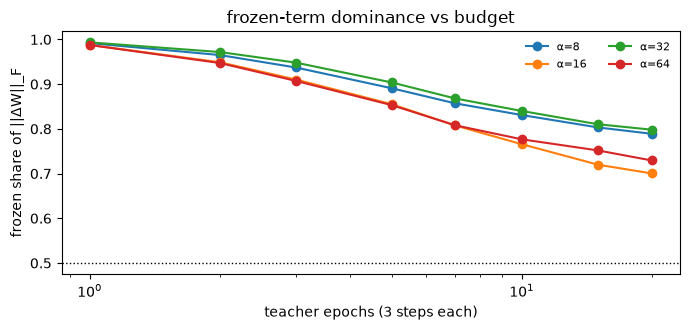

In [7]:
recs = []
for f in (OUT / "teachers").glob("*/pythia-160m*/*/ftseed1/eval/teacher_term_norms.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    mods = r.get("modules") or []
    fro_f = np.nanmean([m.get("B_Ainit_fro", np.nan) for m in mods])
    fro_m = np.nanmean([m.get("B_dA_fro", np.nan) for m in mods])
    recs.append({"param_tag": f.parts[-4], "animal": f.parts[-7], "base": f.parts[-6],
                 "frozen_fro": fro_f, "moved_fro": fro_m,
                 "cos_ok": np.nanmean([m.get("cos_Ainit_Afinal", np.nan) for m in mods]),
                 "cos_wrong": np.nanmean([m.get("cos_wrongseed_Afinal", np.nan) for m in mods])})
tn = pd.DataFrame(recs)
if len(tn):
    tn = hp_cols(tn)
    tn["frozen_share"] = tn.frozen_fro / (tn.frozen_fro + tn.moved_fro)
    print(f"{len(tn)} term-anatomy records; A_init reconstruction valid: right-seed cos "
          f"median {tn.cos_ok.median():.3f} vs wrong-seed {tn.cos_wrong.median():.3f}")
    piv = tn.pivot_table(index="ep", columns="alpha", values="frozen_share", aggfunc="median")
    print("\nmedian frozen share of ||ΔW||_F by epoch x alpha:")
    display(piv.round(3))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for al, g in tn.groupby("alpha"):
        gg = g.groupby("ep").frozen_share.median()
        ax.plot(gg.index, gg.values, marker="o", ms=6, label=f"α={al}")
    ax.axhline(0.5, color="k", ls=":", lw=1)
    ax.set(xlabel="teacher epochs (3 steps each)", ylabel="frozen share of ||ΔW||_F",
           title="frozen-term dominance vs budget")
    ax.set_xscale("log")
    ax.legend(frameon=False, fontsize=8, ncols=2)
    plt.tight_layout(); plt.show()
else:
    print("no teacher_term_norms records yet (teacher-term-norms-A still draining)")

## §5 — the term splice (Tier B): which term carries the collapse?

From `{run}/eval/teacher_term_splice.json`: probe KL under the full update vs frozen-only
vs moved-only, on 57 teachers (47 boundary + 5 deep-dead + 5 clean).

**Verdict (2026-08-21): the damage is in the INTERACTION.** Across the 52 damaged
teachers, the best single term reproduces a median 18% of the full KL (frozen-only median
0.46, moved-only 0.32, full 4.69); frozen ≥ moved in 31/52 — no clean single-term carrier.
Combined with §4 (frozen term = 0.79–0.99 of the update's NORM), the picture is: the
frozen term dominates the size, but collapse at few steps requires the composed update —
super-additive damage, structurally different from the students' single-term trait
dissociation. This also retires the simple "b ≈ frozen-α-exponent ⇒ frozen term carries
teacher collapse" reading (whose b evidence was design-confounded anyway, §3b).

57 splice records


,n,frozen_med,moved_med,single_share_med,frozen_dominant
kl_full,,,,,
"(0, 1]",5,0.01,0.00,0.95,5
"(1, 4]",24,0.34,0.10,0.18,17
"(4, 15]",23,0.56,0.36,0.12,14
"(15, 100]",5,22.50,80.95,0.93,0


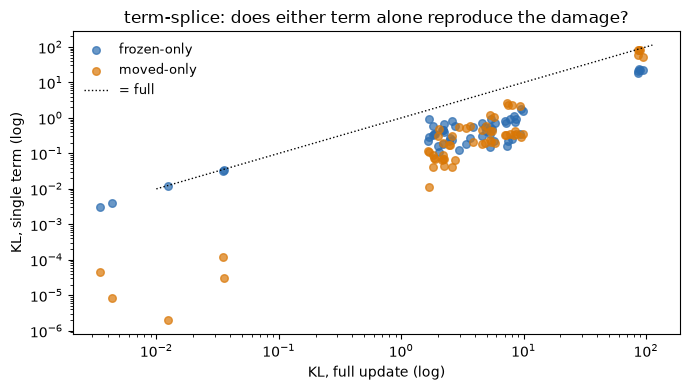

In [8]:
recs = []
for f in (OUT / "teachers").glob("*/pythia-160m*/*/ftseed1/eval/teacher_term_splice.json"):
    try:
        r = json.loads(f.read_text())
    except (json.JSONDecodeError, OSError):
        continue
    recs.append({"param_tag": f.parts[-4], **{k: r.get(k) for k in
                 ("kl_full", "kl_frozen_only", "kl_moved_only")}})
ts = pd.DataFrame(recs).dropna()
if len(ts):
    ts = hp_cols(ts)
    ts["max_single"] = ts[["kl_frozen_only", "kl_moved_only"]].max(axis=1)
    ts["dominant"] = np.where(ts.kl_frozen_only >= ts.kl_moved_only, "frozen", "moved")
    ts["single_share"] = ts.max_single / ts.kl_full
    print(f"{len(ts)} splice records")
    display(ts.groupby(pd.cut(ts.kl_full, [0, 1, 4, 15, 100]), observed=True)
              .agg(n=("kl_full", "size"), frozen_med=("kl_frozen_only", "median"),
                   moved_med=("kl_moved_only", "median"),
                   single_share_med=("single_share", "median"),
                   frozen_dominant=("dominant", lambda s: int((s == "frozen").sum())))
              .round(2))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(ts.kl_full, ts.kl_frozen_only, s=30, alpha=0.7, color="#2b6cb0",
               label="frozen-only")
    ax.scatter(ts.kl_full, ts.kl_moved_only, s=30, alpha=0.7, color="#d97706",
               label="moved-only")
    lim = max(ts.kl_full.max(), 1) * 1.2
    ax.plot([1e-2, lim], [1e-2, lim], color="k", lw=1, ls=":", label="= full")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="KL, full update (log)", ylabel="KL, single term (log)",
           title="term-splice: does either term alone reproduce the damage?")
    ax.legend(frameon=False, fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("no teacher_term_splice records yet (teacher-term-splice-B still draining)")

### Construction notes / open items

- ftseed1 only throughout (the only seed that is pooled/distilled); pp1 probe; declared
  cut 4.0 shared with the student stack; per-run records are the SSOT and every section
  self-updates as the teacher queues drain.
- Teacher budgets are 3–60 steps: the law comparison to students is a two-regime
  (ballistic vs diffusive) comparison, not a like-for-like refit; the budget-bridge
  training campaign (teachers at ep60–2000) is the designed follow-up, unqueued.
- ws1 trees: law fits only until the `dog-*-numgen-top10` chains produce ws1 pools.
- The teacher HP grid was selection-designed, not law-designed — exponent estimates carry
  design-composition caveats a strip-style teacher sweep would remove.